# Hands-on Reinforcement Learning (RL): From Bandits to Deep Q-Networks

**Duration:** 2 hours | **Platform:** Google Colab (CPU runtime is enough) | **Level:** beginner to intermediate

**Course Name:** Executive Training Programme on Trustworthy AI for DRDO Scientists

**Instructor:** Dr. Sabyasachi Mukhopadhyay, Department of Computer Science and Engineering, IIT Kharagpur

## What you will build today

| Part | Topic | What you will do |
|---|---|---|
| 0 | Setup | Install and import the libraries |
| 1 | The RL loop | Let a random agent play CartPole and read its observations, actions and rewards |
| 2 | Multi-armed bandits | Compare greedy and epsilon-greedy exploration on a 10-armed bandit |
| 3 | Markov Decision Process (MDP) and dynamic programming | Solve FrozenLake exactly with Value Iteration |
| 4 | Q-learning | Learn FrozenLake from experience alone, with no model of the environment |
| 5 | Deep Q-Network (DQN) | Train a neural network agent to balance a pole |
| 6 | Wrap-up and exercises | Summary, take-home exercises |

## How to use this notebook

* Run the cells **in order** with `Shift + Enter`.
* Every line of code has a comment that explains it.
* After each code cell there is a **"Reading the output"** box that explains what you should see and what it means.
* A fixed random seed (`SEED = 42`) is used, so your numbers should be close to the ones described. Small differences across library versions are normal.

## The one idea behind everything today

An **agent** interacts with an **environment** in a loop:

1. The agent observes the current **state** $s_t$.
2. It chooses an **action** $a_t$ using its **policy** $\pi$.
3. The environment returns a **reward** $r_{t+1}$ and the next state $s_{t+1}$.

The agent's goal is to maximise the **return**, the (discounted) sum of future rewards:

$$G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots, \qquad 0 \le \gamma \le 1$$

**Interpreting the equation.** The return $G_t$ is the total reward the agent will collect from time $t$ onwards, where every future reward is shrunk by a factor $\gamma$ for each step it lies in the future. A reward that arrives $k$ steps later is worth only $\gamma^k$ times a reward received now. The same sum can be written compactly as $G_t = \sum_{k=0}^{\infty} \gamma^k\, r_{t+k+1}$, or recursively as $G_t = r_{t+1} + \gamma\, G_{t+1}$ ("the next reward, plus the discounted return from the next step"). This recursive form is the seed of every Bellman equation used later.

| Symbol | Meaning |
|---|---|
| $G_t$ | The **return** from time step $t$: the quantity the agent tries to maximise |
| $t$ | The current time step (the moment the agent makes a decision) |
| $r_{t+1}$ | The reward received **after** taking action $a_t$ in state $s_t$. It carries the index $t+1$ because it arrives together with the next state $s_{t+1}$ |
| $r_{t+2}, r_{t+3}, \dots$ | Rewards received further in the future |
| $\gamma$ | The **discount factor**, a number between 0 and 1 |
| $\gamma^k$ | The weight given to a reward $k$ steps ahead; it shrinks geometrically with $k$ |
| $\dots$ | The sum continues until the episode ends (or forever, for a task that never ends) |
| $0 \le \gamma \le 1$ | Keeps the weights between 0 and 1; with $\gamma < 1$ an infinite sum of bounded rewards stays finite |

*Worked example:* with $\gamma = 0.9$ and three rewards of $1$, the return is $1 + 0.9 + 0.81 = 2.71$. In CartPole with $\gamma = 1$, every step gives $+1$, so the return is simply the number of steps survived.

The **discount factor** $\gamma$ controls how much the agent cares about the future: $\gamma = 0$ means only the next reward matters, and $\gamma$ close to 1 means long-term rewards matter almost as much as immediate ones.

---
# Part 0. Setup

Gymnasium is the maintained successor of OpenAI Gym. It provides standard RL environments with one common interface (`reset` and `step`). PyTorch is used in Part 5 for the neural network. Both are usually pre-installed in Colab; the cell below makes sure Gymnasium is present.

In [1]:
# Install Gymnasium quietly (-q hides the long install log); in Colab this takes a few seconds or is already satisfied
!pip install -q gymnasium

#### Reading the output

**What you see:** in this run the cell printed nothing. The `-q` (quiet) flag hides the normal installation log, so an empty output means Gymnasium was installed successfully or was already present.

**What it means:**
* No output, or a single "Requirement already satisfied" line, is a success.
* Red text starting with `ERROR` means the installation failed. Re-run the cell, or restart the runtime (`Runtime → Restart session`) and run it again.
* A yellow `WARNING` about dependency versions is usually harmless for this notebook.

In [2]:
import random                      # Python's built-in random module, used for epsilon-greedy coin flips
import time                        # used to measure how long training takes
from collections import deque      # a fast double-ended queue, used later as the replay buffer

import numpy as np                 # numerical arrays, maths and random numbers
import matplotlib.pyplot as plt    # plotting learning curves and value maps
import gymnasium as gym            # the RL environments (CartPole, FrozenLake)
import torch                       # deep-learning library used in Part 5
import torch.nn as nn              # neural-network building blocks (layers, losses)
import torch.optim as optim        # optimisers such as Adam

SEED = 42                          # one fixed seed so everyone in the room gets similar numbers
random.seed(SEED)                  # seed Python's random generator
np.random.seed(SEED)               # seed NumPy's random generator
torch.manual_seed(SEED)            # seed PyTorch's random generator (network weights, sampling)

plt.rcParams["figure.figsize"] = (8, 4)   # default size of every plot (width, height in inches)

print("Gymnasium version:", gym.__version__)   # confirm Gymnasium loaded and show its version
print("PyTorch version:  ", torch.__version__) # confirm PyTorch loaded and show its version

Gymnasium version: 1.4.0
PyTorch version:   2.14.1+cpu


#### Reading the output

**What you see:**
```
Gymnasium version: 1.4.0
PyTorch version:   2.14.1+cpu
```

**What it means:**
* Both libraries were imported without error, so the environment is ready for every part of the notebook.
* `+cpu` shows that this PyTorch build runs on the processor only. That is enough here, because the DQN network in Part 5 is tiny (about 17,000 weights) and a Graphics Processing Unit (GPU) would give little speed-up.
* No text was printed by the three `seed` calls. They silently fix the random number generators so that the results described in this notebook can be reproduced. Other library versions may change the exact numbers slightly, but not the conclusions.

---
# Part 1. The RL loop with a random agent

**CartPole:** a pole is hinged on a cart that moves along a track. At every time step the agent pushes the cart **left (action 0)** or **right (action 1)**. The agent receives **+1 reward for every step the pole stays up**. The episode ends when the pole tilts more than about 12°, when the cart leaves the track (**terminated**), or after 500 steps (**truncated**). So the return of an episode equals the number of steps survived, and 500 is the maximum.

First, let us look at what the agent can **see** and **do**.

In [3]:
env = gym.make("CartPole-v1")                       # create the CartPole environment (version 1, 500-step limit)

print("Observation space:", env.observation_space)  # what the agent sees: a Box of 4 real numbers
print("Action space:     ", env.action_space)       # what the agent can do: Discrete(2) means actions 0 and 1

obs, info = env.reset(seed=SEED)                    # start a new episode; returns the first observation and an info dict
print("\nFirst observation:", np.round(obs, 4))     # print the 4 numbers, rounded to 4 decimals for readability
print("Meaning: [cart position, cart velocity, pole angle (rad), pole angular velocity]")  # label each number

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space:      Discrete(2)

First observation: [ 0.0274 -0.0061  0.0359  0.0197]
Meaning: [cart position, cart velocity, pole angle (rad), pole angular velocity]


#### Reading the output

**What you see:**
* `Observation space: Box([-4.8, -inf, -0.4189, -inf], [4.8, inf, 0.4189, inf], (4,), float32)`
* `Action space: Discrete(2)`
* `First observation: [ 0.0274 -0.0061  0.0359  0.0197]`

**What it means, line by line:**

| Output | Interpretation |
|---|---|
| `Box(low, high, (4,), float32)` | The agent sees a vector of **4 continuous numbers**. The first array gives their lower limits and the second their upper limits |
| `±4.8` (cart position) | The range of positions the observation can report. The episode actually ends earlier, when the cart passes ±2.4 |
| `±0.4189` (pole angle) | 0.4189 rad = 24°. The episode ends at about ±0.21 rad (12°), half this limit |
| `±inf` (the two velocities) | Velocities have no hard limit in the observation |
| `Discrete(2)` | Exactly **2 actions**: 0 = push the cart left, 1 = push it right |
| `0.0274` | The cart starts 2.7 cm to the right of the centre of the track |
| `-0.0061` | It is moving very slowly to the left |
| `0.0359` | The pole leans 0.0359 rad (about 2.1°) to the right |
| `0.0197` | The pole is already rotating further to the right, so without a correcting push it will fall right |

**Key point:** the four numbers are continuous, so the agent can meet an infinite number of different states. A table with one entry per state is impossible, which is why Part 5 uses a neural network.

Now one complete episode, step by step. The agent chooses actions **at random**, so it has no intelligence at all. This shows the bare interaction loop that every RL algorithm in this notebook is built on.

In [4]:
env.action_space.seed(SEED)                     # seed the action sampler so the random actions are reproducible
obs, info = env.reset(seed=SEED)                # start a fresh episode
total_reward = 0.0                              # running sum of rewards, i.e. the return of this episode
step = 0                                        # counts the time steps
done = False                                    # becomes True when the episode ends

while not done:                                 # keep interacting until the episode ends
    action = env.action_space.sample()          # random policy: pick 0 or 1 with equal probability
    obs, reward, terminated, truncated, info = env.step(action)  # send the action, receive the outcome
    total_reward += reward                      # add this step's reward (+1) to the return
    step += 1                                   # move to the next time step
    if step <= 5:                               # print only the first 5 steps to keep the output short
        print(f"step {step}: action={action}, reward={reward}, pole angle={obs[2]:+.4f} rad")
    done = terminated or truncated              # terminated = pole fell / cart left track; truncated = hit 500 steps

print(f"\nEpisode finished after {step} steps, return = {total_reward}")  # summary of the whole episode
print("terminated (failure):", terminated, "| truncated (time limit):", truncated)  # why the episode ended

step 1: action=0, reward=1.0, pole angle=+0.0363 rad
step 2: action=1, reward=1.0, pole angle=+0.0427 rad
step 3: action=1, reward=1.0, pole angle=+0.0436 rad
step 4: action=0, reward=1.0, pole angle=+0.0388 rad
step 5: action=0, reward=1.0, pole angle=+0.0402 rad

Episode finished after 30 steps, return = 30.0
terminated (failure): True | truncated (time limit): False


#### Reading the output

**What you see:** five lines for the first five steps, then a summary: `Episode finished after 30 steps, return = 30.0` and `terminated (failure): True | truncated (time limit): False`.

**What it means:**
* **Reward:** every step gives `reward=1.0`, because the pole is still up. So the return equals the number of steps survived (30 here).
* **Pole angle:** it starts at +0.0359 rad and stays between +0.036 and +0.044 rad during the first five steps. The actions alternate at random (0, 1, 1, 0, 0), so the pushes partly cancel out and never deliberately correct the rightward lean.
* **Delayed effect of an action:** the angle reacts to a push one step late. For example, the push right at step 3 only shows up as the drop from +0.0436 to +0.0388 at step 4. A push first changes the pole's angular velocity, and only then its angle. A good controller must anticipate, not just react.
* **How it ended:** after 30 steps `terminated` is `True` and `truncated` is `False`. The pole fell past 12° (or the cart left the track). The episode did not reach the 500-step time limit.

**Key point:** every algorithm in this notebook uses exactly this loop: observe the state, choose an action, call `env.step(action)`, and receive `(next_state, reward, terminated, truncated, info)`. Only two things change from one algorithm to the next: **how the action is chosen** and **what is learned from the reward**.

Random agent over 100 episodes: mean return = 22.9, min = 9, max = 83


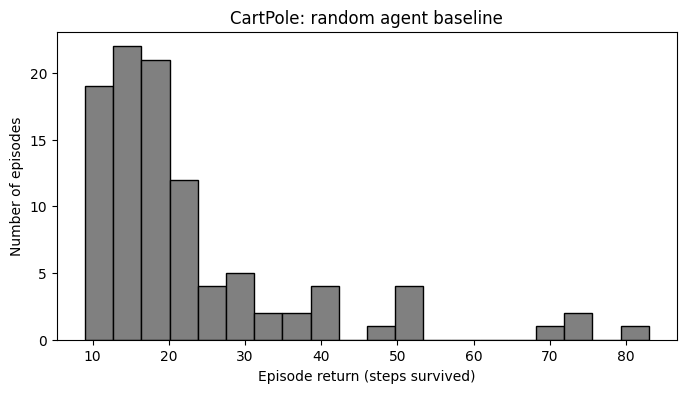

In [5]:
def run_random_episode(env, seed):
    # Play one episode with random actions and return the total reward
    obs, info = env.reset(seed=seed)            # start a new episode with the given seed
    total, done = 0.0, False                    # return accumulator and end-of-episode flag
    while not done:                             # loop until the episode ends
        obs, r, term, trunc, info = env.step(env.action_space.sample())  # act randomly
        total += r                              # accumulate the reward
        done = term or trunc                    # check whether the episode is over
    return total                                # the episode return (= number of steps survived)

random_returns = [run_random_episode(env, SEED + i) for i in range(100)]  # play 100 random episodes
print(f"Random agent over 100 episodes: mean return = {np.mean(random_returns):.1f}, "
      f"min = {min(random_returns):.0f}, max = {max(random_returns):.0f}")  # summary statistics

plt.hist(random_returns, bins=20, color="grey", edgecolor="black")   # histogram of the 100 returns
plt.xlabel("Episode return (steps survived)")    # x-axis label
plt.ylabel("Number of episodes")                 # y-axis label
plt.title("CartPole: random agent baseline")     # plot title
plt.show()                                       # display the figure

#### Reading the output

**What you see:** `Random agent over 100 episodes: mean return = 22.9, min = 9, max = 83`, and a histogram of the 100 returns.

**What it means:**
* **Typical behaviour:** about three quarters of the episodes (74 of 100) end within roughly 25 steps. The tallest bars sit between 10 and 20 steps.
* **Minimum of 9:** even the worst random sequence survives 9 steps. That is roughly how long the pole takes to fall from upright when it is pushed the wrong way every time.
* **Long right tail:** a few lucky episodes last 50 to 83 steps, which pulls the mean (22.9) above the typical value. The histogram is **right-skewed**: most episodes fail quickly, and a few survive by chance.
* **Far from the ceiling:** the best random episode (83) is still far below the 500-step maximum.

**Key point:** **22.9 is the baseline.** A learning agent has learned something only if it clearly and consistently beats this number on episodes it was not trained on. Part 5 measures the DQN agent against exactly this value.

**Part 1 takeaway:** the outputs show the complete agent-environment interface (a 4-number state, 2 actions and +1 per step) and set the performance that every learning method must beat.

---
# Part 2. Multi-armed bandits: exploration versus exploitation

Before full RL, consider its simplest special case. A **k-armed bandit** is a row of $k$ slot machines. Each arm $a$ pays a random reward with an unknown mean $q_*(a)$. There is **no state**: each pull is independent. The agent wants to find and keep pulling the best arm.

The dilemma:
* **Exploit:** pull the arm that currently looks best (maximise reward now).
* **Explore:** try other arms (gain information that may pay off later).

**Epsilon-greedy policy:** with probability $\varepsilon$ pick a random arm (explore), otherwise pick the arm with the highest estimated value (exploit).

Each arm's value is estimated by the running average of its rewards, updated incrementally:

$$Q_{n+1}(a) = Q_n(a) + \frac{1}{N(a)}\big(R - Q_n(a)\big)$$

**Interpreting the equation.** After pulling arm $a$ and receiving reward $R$, the estimate of that arm is moved towards $R$ by a fraction $1/N(a)$ of the gap. With this particular step size the result is exactly the **average of all rewards received from arm $a$ so far**, computed without storing the past rewards. Early pulls move the estimate a lot (step size 1, then 1/2, then 1/3, ...), while later pulls only nudge it, because the average is already based on many samples.

| Symbol | Meaning |
|---|---|
| $a$ | The arm that was just pulled (only this arm's estimate changes) |
| $Q_n(a)$ | The **old estimate** of arm $a$'s mean reward, before this pull |
| $Q_{n+1}(a)$ | The **new estimate**, after including the latest reward |
| $R$ | The reward just received from arm $a$ (the **target**) |
| $N(a)$ | The number of times arm $a$ has been pulled, **including** this pull (in the code `N[a] += 1` happens before the update) |
| $\frac{1}{N(a)}$ | The **step size**: how far the estimate moves towards the target |
| $R - Q_n(a)$ | The **prediction error**: positive if the arm paid more than expected, negative if it paid less |

*Worked example:* if $Q_n(a) = 0.5$, this is the 4th pull of arm $a$ ($N(a) = 4$) and $R = 1.3$, then $Q_{n+1}(a) = 0.5 + \tfrac{1}{4}(1.3 - 0.5) = 0.7$.

This **"new estimate = old estimate + step size × (target − old estimate)"** pattern reappears in Q-learning and DQN.

Simulation took 44.9 s


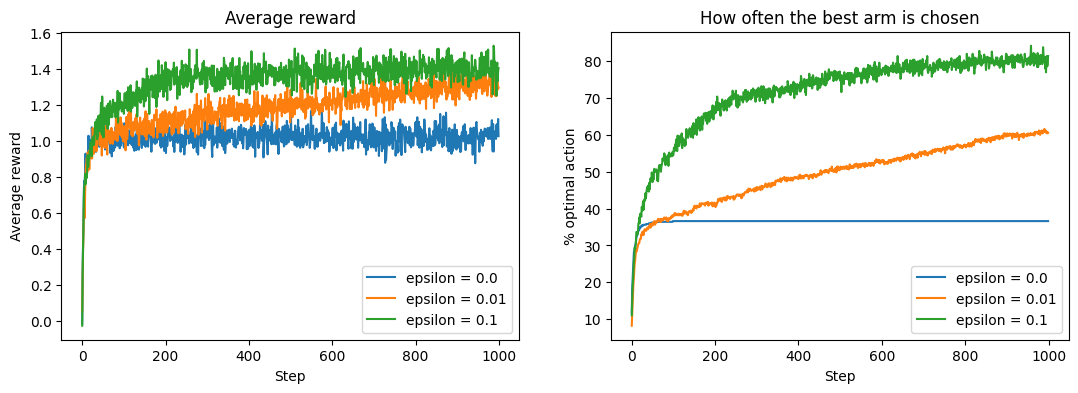

epsilon=0.0   reward(last 100)=1.025  optimal action(last 100)=36.6%
epsilon=0.01  reward(last 100)=1.314  optimal action(last 100)=60.2%
epsilon=0.1   reward(last 100)=1.395  optimal action(last 100)=80.4%


In [6]:
def run_bandit(epsilon, k=10, steps=1000, runs=500, seed=SEED):
    # Simulate an epsilon-greedy agent on many random k-armed bandit problems and average the results
    rng = np.random.default_rng(seed)               # independent random generator for reproducibility
    avg_reward = np.zeros(steps)                    # mean reward at each time step, averaged over runs
    pct_optimal = np.zeros(steps)                   # fraction of runs that picked the best arm at each step
    for run in range(runs):                         # repeat on many different bandit problems
        q_true = rng.normal(0, 1, k)                # true mean reward of each arm, drawn from N(0, 1)
        best_arm = np.argmax(q_true)                # the arm with the highest true mean (unknown to the agent)
        Q = np.zeros(k)                             # agent's estimated value of each arm, starts at 0
        N = np.zeros(k)                             # number of times each arm has been pulled
        for t in range(steps):                      # one pull per time step
            if rng.random() < epsilon:              # with probability epsilon ...
                a = rng.integers(k)                 # ... explore: pick a random arm
            else:                                   # otherwise ...
                a = rng.choice(np.flatnonzero(Q == Q.max()))  # ... exploit: pick the best-looking arm (random tie-break)
            R = rng.normal(q_true[a], 1)            # reward is noisy: true mean plus N(0, 1) noise
            N[a] += 1                               # one more pull of arm a
            Q[a] += (R - Q[a]) / N[a]               # incremental average update of arm a's estimate
            avg_reward[t] += R                      # accumulate reward at step t
            pct_optimal[t] += (a == best_arm)       # accumulate 1 if the best arm was chosen
    return avg_reward / runs, 100 * pct_optimal / runs   # average over runs; convert optimal fraction to %

t0 = time.time()                                    # start a timer
results = {eps: run_bandit(eps) for eps in [0.0, 0.01, 0.1]}   # three agents: greedy, a little, more exploration
print(f"Simulation took {time.time() - t0:.1f} s")  # report the elapsed time

fig, axes = plt.subplots(1, 2, figsize=(13, 4))     # two side-by-side plots
for eps, (rew, opt) in results.items():             # one curve per epsilon value
    axes[0].plot(rew, label=f"epsilon = {eps}")     # average reward over time
    axes[1].plot(opt, label=f"epsilon = {eps}")     # % of times the best arm was chosen
axes[0].set(xlabel="Step", ylabel="Average reward", title="Average reward")  # labels for the left plot
axes[1].set(xlabel="Step", ylabel="% optimal action", title="How often the best arm is chosen")  # right plot
for ax in axes: ax.legend()                         # add legends to both plots
plt.show()                                          # display the figure

for eps, (rew, opt) in results.items():             # print a numeric summary of the last 100 steps
    print(f"epsilon={eps:<5} reward(last 100)={rew[-100:].mean():.3f}  optimal action(last 100)={opt[-100:].mean():.1f}%")

#### Reading the output

**What you see:** the simulation time (`44.9 s` for 3 agents × 500 bandit problems × 1,000 pulls), two plots and a summary of the last 100 steps:

| Agent | Average reward (last 100 steps) | Best arm chosen (last 100 steps) |
|---|---|---|
| Greedy (ε = 0) | 1.025 | 36.6% |
| ε = 0.01 | 1.314 | 60.2% |
| ε = 0.1 | **1.395** | **80.4%** |

**Left plot (average reward):**
* All three curves rise steeply in the first few dozen steps, as each agent quickly moves away from its initial estimates of 0.
* The **blue greedy** curve then goes flat at about 1.0 and never improves.
* The **green ε = 0.1** curve climbs highest, reaching about 1.4 by step 200 and staying there.
* The **orange ε = 0.01** curve climbs slowly but steadily, and by step 1,000 it has almost caught up with green.
* The jagged look is reward noise: every pull adds random noise with a standard deviation of 1.

**Right plot (how often the best arm is chosen):**
* **Greedy becomes a perfectly flat line at 36.6% after about 50 steps.** Each greedy run has locked onto one arm for good. In about 37% of the problems that arm happens to be the best one, and in the rest it never will be.
* **ε = 0.1** keeps rising, to about 80%. It cannot exceed about 91%, because 10% of its pulls are random and only 1 in 10 of those hits the best arm by chance.
* **ε = 0.01** is still rising at step 1,000 (60%). Because it wastes only 1% of its pulls, over a much longer run it would overtake ε = 0.1.

**Why the reward ceiling is about 1.54:** the true arm means are drawn from N(0, 1). The best of 10 such arms has an expected value of about 1.54, so an agent that always pulled the best arm would earn about 1.54 per step. ε = 0.1 earns 1.395, about 90% of this ideal. Greedy earns 1.025, about two thirds of it.

**Key point:** the greedy agent did not fail because it learned badly. It failed because it **stopped collecting information**. Exploration is the price of discovering better options, and the right amount depends on how long the agent will keep acting.

**Part 2 takeaway:** in this experiment, exploring 10% of the time almost doubled how often the best arm was chosen (80.4% against 36.6%) and raised the reward by about 36%.

---
# Part 3. Markov Decision Processes and Value Iteration

Bandits have no state. Real problems do: an action changes the situation the agent faces next. This is formalised as a **Markov Decision Process (MDP)**: a set of states $S$, actions $A$, transition probabilities $P(s' \mid s, a)$, rewards $R$ and a discount $\gamma$.

**FrozenLake 4×4:** the agent walks on a frozen lake from **S** (start, top-left) to **G** (goal, bottom-right). **F** is frozen (safe) and **H** is a hole (the episode ends with reward 0). Reaching **G** gives **reward 1**; every other step gives 0. With `is_slippery=True` the ice is slippery: the agent moves in the intended direction only **1/3 of the time** and slides to one of the two perpendicular directions otherwise.

When the full model $P$ is known, we can compute the optimal values directly with the **Bellman optimality equation**:

$$V^*(s) = \max_a \sum_{s'} P(s' \mid s,a)\,\big[R(s,a,s') + \gamma\, V^*(s')\big]$$

**Interpreting the equation.** The value of a state, when the agent behaves optimally, equals the value of its **best action**. The value of an action is a one-step look-ahead: for every place $s'$ the agent might land, take the immediate reward plus the discounted value of $s'$, and weight it by the probability of landing there. In words: *"look one step ahead, average over where the slippery ice might send you, and pick the action with the best average."* Because $V^*$ appears on both sides, the equation is solved by repeating it until the numbers stop changing, which is exactly what Value Iteration does.

| Symbol | Meaning |
|---|---|
| $V^*(s)$ | The **optimal value** of state $s$: the expected return when starting in $s$ and acting optimally from then on |
| $s$ | The current state (a cell of the lake) |
| $a$ | A candidate action (Left, Down, Right, Up) |
| $\max_a$ | Choose the action that gives the largest expected value (this is what makes it the *optimality* equation) |
| $s'$ | A possible next state |
| $\sum_{s'}$ | Add up over all possible next states: an **expectation** over the randomness of the environment |
| $P(s' \mid s,a)$ | The **transition probability**: the chance of landing in $s'$ after taking action $a$ in $s$ (1/3 for each outcome on slippery ice) |
| $R(s,a,s')$ | The immediate reward for that transition (1 when $s'$ is the goal, otherwise 0) |
| $\gamma$ | The discount factor; it makes values decay with distance to the goal |
| $V^*(s')$ | The optimal value of the next state, taken as 0 if $s'$ is a hole or the goal (the episode ends there; this is the `(not term)` factor in the code) |
| $\big[R + \gamma V^*(s')\big]$ | What one particular outcome is worth: reward now plus discounted value afterwards |
| $\sum_{s'} P(\cdot)\,[\cdot]$ | The expected value of taking action $a$ in $s$, also called the optimal action value $Q^*(s,a)$ |

*Worked example:* pressing Right in state 0 leads to states 1, 4 or 0, each with probability 1/3 and reward 0, so its value is $\tfrac{\gamma}{3}\big(V^*(1) + V^*(4) + V^*(0)\big)$. $V^*(0)$ is the largest of the four such action values.

**Value Iteration** applies this equation repeatedly to every state until the values stop changing.

In [7]:
lake = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="ansi")  # slippery 4x4 lake, text rendering
lake.reset(seed=SEED)                               # reset once so the map can be drawn
print(lake.render())                                # print the map: S start, F frozen, H hole, G goal

n_states = lake.observation_space.n                 # number of states: 16 cells numbered 0..15, row by row
n_actions = lake.action_space.n                     # number of actions: 4 (0 Left, 1 Down, 2 Right, 3 Up)
print("States:", n_states, "| Actions:", n_actions) # confirm the sizes

P = lake.unwrapped.P                                # the full transition model: P[state][action] = list of outcomes
print("\nOutcomes of pressing Right (2) in state 0:")  # inspect one entry of the model
for prob, next_s, reward, terminal in P[0][2]:      # each outcome is (probability, next state, reward, episode ends?)
    print(f"  prob={prob:.3f} -> next state {next_s}, reward {reward}, terminal {terminal}")


SFFF
FHFH
FFFH
HFFG

States: 16 | Actions: 4

Outcomes of pressing Right (2) in state 0:
  prob=0.333 -> next state 4, reward 0, terminal False
  prob=0.333 -> next state 1, reward 0, terminal False
  prob=0.333 -> next state 0, reward 0, terminal False


#### Reading the output

**What you see:** the 4×4 map, the sizes `States: 16 | Actions: 4`, and the three possible outcomes of pressing Right in state 0.

**The map:**
```
SFFF     states  0  1  2  3
FHFH             4  5  6  7
FFFH             8  9 10 11
HFFG            12 13 14 15
```
* The highlighted (red) `S` is the agent's current position, the start state 0.
* There are holes at states 5, 7, 11 and 12, and the goal is at state 15.
* Notice that the goal is surrounded on two sides (states 11 and 12 nearby are holes). Every route to it passes close to a hole.

**The model entry `P[0][2]` (Right in state 0):**

| Probability | Next state | Physical meaning |
|---|---|---|
| 0.333 | 4 | Slid **down** (perpendicular to the intended direction) |
| 0.333 | 1 | Moved **right**, as intended |
| 0.333 | 0 | Slid **up** into the wall, so stayed in place |

All three outcomes give reward 0, and none is terminal, so this particular move is safe even though it is unpredictable.

**Key point:** the environment is **stochastic**: the intended move succeeds only 1/3 of the time. A good policy therefore cannot simply be "walk the shortest path". It must choose actions whose *possible slips* avoid the holes.

Converged after 324 sweeps

Optimal state values V*(s):
[[0.542 0.499 0.471 0.457]
 [0.558 0.    0.358 0.   ]
 [0.592 0.643 0.615 0.   ]
 [0.    0.742 0.863 0.   ]]

Optimal policy (H = hole, G = goal):
← ↑ ↑ ↑
← H ← H
↑ ↓ ← H
H → ↓ G


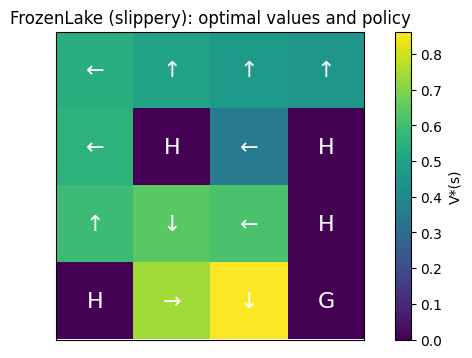

In [8]:
def value_iteration(P, n_states, n_actions, gamma=0.99, theta=1e-8):
    # Compute optimal state values V* and a greedy optimal policy using the Bellman optimality equation
    V = np.zeros(n_states)                          # start with all state values equal to 0
    sweeps = 0                                      # counts full passes over all states
    while True:                                     # repeat until values converge
        delta = 0.0                                 # largest change in any state value during this sweep
        for s in range(n_states):                   # update every state
            q = np.zeros(n_actions)                 # value of each action in state s
            for a in range(n_actions):              # look at every action
                for prob, s2, r, term in P[s][a]:   # and every possible outcome of that action
                    q[a] += prob * (r + gamma * V[s2] * (not term))  # expected reward + discounted next value
            best = q.max()                          # Bellman optimality: take the best action's value
            delta = max(delta, abs(best - V[s]))    # track how much this state's value changed
            V[s] = best                             # update the value in place
        sweeps += 1                                 # one more sweep completed
        if delta < theta:                           # stop when no value changed by more than theta
            break
    policy = np.zeros(n_states, dtype=int)          # greedy policy extracted from the final values
    for s in range(n_states):                       # for every state ...
        q = [sum(p * (r + gamma * V[s2] * (not t)) for p, s2, r, t in P[s][a]) for a in range(n_actions)]
        policy[s] = int(np.argmax(q))               # ... choose the action with the highest expected value
    return V, policy, sweeps                        # return values, policy and number of sweeps needed

V_star, pi_star, sweeps = value_iteration(P, n_states, n_actions)   # solve the slippery lake
print(f"Converged after {sweeps} sweeps\n")         # how many sweeps value iteration needed

arrows = np.array(["←", "↓", "→", "↑"])             # symbols for actions 0, 1, 2, 3
desc = lake.unwrapped.desc.astype(str)              # the map letters as a 4x4 array of strings
print("Optimal state values V*(s):")                # print the value grid
print(np.round(V_star.reshape(4, 4), 3))            # reshape the 16 values into the 4x4 map layout
print("\nOptimal policy (H = hole, G = goal):")     # print the policy grid
for row in range(4):                                # one line per row of the map
    print(" ".join(desc[row, c] if desc[row, c] in "HG" else arrows[pi_star[row * 4 + c]] for c in range(4)))

plt.imshow(V_star.reshape(4, 4), cmap="viridis")    # heat map of state values
plt.colorbar(label="V*(s)")                         # colour scale
for s in range(n_states):                           # write the letter or arrow on each cell
    r, c = divmod(s, 4)                             # convert state number to (row, column)
    label = desc[r, c] if desc[r, c] in "HG" else arrows[pi_star[s]]
    plt.text(c, r, label, ha="center", va="center", color="white", fontsize=16)
plt.title("FrozenLake (slippery): optimal values and policy")  # plot title
plt.xticks([]); plt.yticks([])                      # hide axis ticks
plt.show()                                          # display the figure

#### Reading the output

**What you see:** `Converged after 324 sweeps`, the 4×4 grid of optimal values $V^*(s)$, the optimal policy as arrows, and a heat map that combines both.

**1. Convergence (324 sweeps).** Value iteration repeated the Bellman update over all 16 states 324 times, until no value changed by more than `theta = 1e-8`. It takes this many sweeps because with $\gamma = 0.99$ the information about the goal must travel back through many small, discounted steps.

**2. The value grid.**
```
[[0.542 0.499 0.471 0.457]
 [0.558 0.    0.358 0.   ]
 [0.592 0.643 0.615 0.   ]
 [0.    0.742 0.863 0.   ]]
```
* Each number is the expected discounted return from that cell under the best policy. Because the only reward is 1 at the goal, it is close to the **chance of eventually reaching the goal**.
* **Start state: 0.542.** Acting optimally from the start, the agent's expected discounted return is 0.54 (it reaches the goal a little under 3 times out of 4, but discounting lowers the number).
* **Highest values: state 14 (0.863) and state 13 (0.742)**, next to the goal. These are the bright yellow and green cells in the heat map.
* **Lowest non-zero value: state 6 (0.358).** It sits between holes 5 and 7, so every action risks a slip into a hole.
* **Zeros:** holes and the goal are terminal, so no future reward can be collected from them. The goal is valuable to *enter*, not to stand on.
* The **left-hand column** (0.542, 0.558, 0.592) is safer than the **top row** to its right (0.499, 0.471, 0.457). The safe route runs down the left edge.

**3. The policy.**
```
← ↑ ↑ ↑
← H ← H
↑ ↓ ← H
H → ↓ G
```
Many arrows point **into walls**. This is deliberate, not a bug:
* **State 0 (←):** pushing into the left wall means the agent either stays put or slides down (state 4) or up (wall). It never moves towards the top row, and slowly drifts down the safe left column.
* **Top row (↑):** pushing into the top wall means the agent only slides left or right. It cannot fall into the holes of row 2 (states 5 and 7).
* **State 14 (↓):** pushing into the bottom wall gives 1/3 slide right **into the goal**, 1/3 stay and 1/3 slide left. No outcome is a hole.
* **State 6 (←):** every action here has some chance of hitting a hole. Left (and Right) limit that chance to 1/3, while Down or Up would risk 2/3.

**Key point:** with a known model, dynamic programming finds the exact optimal behaviour. On slippery ice, that behaviour trades **speed for safety**: the agent takes long, wall-hugging routes so that no slip can drop it into a hole.

In [9]:
def evaluate_policy(env, policy, episodes=2000, seed=SEED):
    # Run a fixed tabular policy many times and return the fraction of episodes that reach the goal
    successes = 0                                   # number of episodes that reached G
    for i in range(episodes):                       # many independent episodes
        s, _ = env.reset(seed=seed + i)             # start each episode with a different seed
        done = False                                # end-of-episode flag
        while not done:                             # follow the policy until the episode ends
            s, r, term, trunc, _ = env.step(int(policy[s]))  # take the action the policy prescribes
            done = term or trunc                    # stop on hole, goal or the 100-step limit
        successes += r                              # reward is 1 only when the goal is reached
    return successes / episodes                     # success rate between 0 and 1

random_policy = np.random.randint(0, n_actions, n_states)   # a random (but fixed) policy for comparison
print(f"Random policy success rate:          {evaluate_policy(lake, random_policy):.1%}")  # baseline
print(f"Value-iteration policy success rate: {evaluate_policy(lake, pi_star):.1%}")        # optimal policy

Random policy success rate:          7.0%
Value-iteration policy success rate: 74.1%


#### Reading the output

**What you see:**
```
Random policy success rate:          7.0%
Value-iteration policy success rate: 74.1%
```
Both numbers come from 2,000 test episodes, using the same seeds for both policies.

**What it means:**
* **Random fixed policy: 7.0%.** Only 140 of 2,000 episodes reached the goal, and those mostly by luck.
* **Optimal policy: 74.1%.** About 1,482 of 2,000 episodes reached the goal, more than 10 times the random policy.
* **Why not 100%?** Even with perfect decisions, the ice is random. Roughly 1 episode in 4 still ends in a hole, or reaches the 100-step limit while the agent is safely hugging walls.
* **Link to the values:** the success rate (0.741) is a bit higher than $V^*(0) = 0.542$. $V^*$ discounts rewards that arrive late with $\gamma = 0.99$, while the success rate counts every success equally, however long it took.
* **Sampling uncertainty:** with 2,000 episodes, the margin of error on 74.1% is about ±2 percentage points.

**Key point:** **74.1% is the best success rate any policy can achieve on this map.** It is the ceiling for the model-free Q-learning agent in Part 4.

**Part 3 takeaway:** knowing the transition model $P$ turns the problem into planning. Value iteration gives the exact optimum (74.1%) in a fraction of a second, with no trial and error.

---
# Part 4. Q-learning: learning from experience without a model

Now pretend we **do not know** $P$. The agent learns only by playing and observing rewards. Q-learning learns the **action-value function** $Q(s,a)$, the expected return of taking action $a$ in state $s$ and acting optimally afterwards. After every step it applies:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{TD target}} - Q(s,a)\Big]$$

**Interpreting the equation.** After one real step $(s, a, r, s')$, the agent compares its current guess $Q(s,a)$ with a better-informed guess, the **TD target**: the reward it actually got plus the discounted value of the best action available in the state it actually reached. It then moves its guess a fraction $\alpha$ of the way towards that target. This is a sample-based version of the Bellman equation from Part 3: instead of summing over all next states with the probabilities $P(s' \mid s,a)$, which the agent does not know, it uses the single next state it observed. Averaged over many updates, the random outcomes occur in the right proportions, so $Q$ converges towards $Q^*$.

| Symbol | Meaning |
|---|---|
| $Q(s,a)$ (left side) | The entry of the Q-table being updated: the estimated return of taking action $a$ in state $s$ and acting optimally afterwards |
| $\leftarrow$ | "Is replaced by": an assignment, not an equality |
| $\alpha$ | The **learning rate** (between 0 and 1): the fraction of the error that is corrected in one update. Large $\alpha$ learns fast but is noisy; small $\alpha$ is stable but slow |
| $r$ | The reward actually received for this step |
| $\gamma$ | The discount factor |
| $s'$ | The next state actually observed after taking $a$ |
| $a'$ | Any action that could be taken in $s'$ |
| $\max_{a'} Q(s',a')$ | The value of the best action in the next state, according to the current table. Using the max (not the action the agent will actually take) is what makes Q-learning **off-policy** |
| $r + \gamma \max_{a'} Q(s',a')$ | The **TD target**: a one-step estimate of the return. It is set to just $r$ when $s'$ is terminal (the `(not term)` factor in the code) |
| $Q(s,a)$ (inside the bracket) | The old estimate, before the update |
| $[\,\text{target} - Q(s,a)\,]$ | The **TD error** $\delta$: positive means "better than expected, raise the estimate", negative means "worse than expected, lower it" |

*Worked example:* with $Q(s,a) = 0.40$, $r = 0$, $\gamma = 0.99$, $\max_{a'} Q(s',a') = 0.60$ and $\alpha = 0.1$: target $= 0 + 0.99 \times 0.60 = 0.594$, TD error $= 0.594 - 0.40 = 0.194$, new $Q(s,a) = 0.40 + 0.1 \times 0.194 = 0.4194$.

* $\alpha$ is the **learning rate** (step size).
* The bracket is the **Temporal Difference (TD) error**: how much better or worse the outcome was than expected.
* Q-learning is **off-policy**: it learns the value of the greedy policy while behaving epsilon-greedily for exploration.

Compare this with the bandit update in Part 2: it is the same "old + step size × (target − old)" pattern, with a target that now includes the value of the next state.

Training took 28.0 s


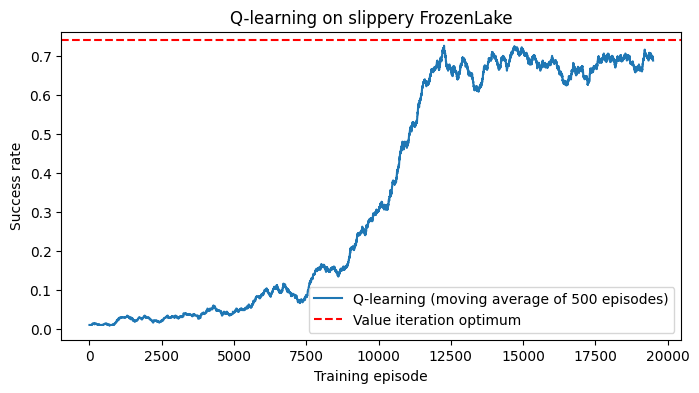

In [10]:
def q_learning(env, episodes=20000, alpha=0.1, gamma=0.99,
               eps_start=1.0, eps_end=0.01, eps_decay_frac=0.6, seed=SEED):
    # Tabular Q-learning with an epsilon-greedy behaviour policy and linearly decaying epsilon
    rng = np.random.default_rng(seed)               # random generator for exploration decisions
    Q = np.zeros((env.observation_space.n, env.action_space.n))  # Q-table: one row per state, one column per action
    rewards = np.zeros(episodes)                    # reward (1 = goal reached) of each training episode
    decay_episodes = int(eps_decay_frac * episodes) # number of episodes over which epsilon falls to eps_end
    for ep in range(episodes):                      # one training episode per iteration
        eps = max(eps_end, eps_start - (eps_start - eps_end) * ep / decay_episodes)  # current exploration rate
        s, _ = env.reset(seed=seed + ep)            # start a new episode
        done = False                                # end-of-episode flag
        while not done:                             # interact until the episode ends
            if rng.random() < eps:                  # explore with probability eps ...
                a = int(rng.integers(env.action_space.n))         # ... random action
            else:                                   # otherwise exploit ...
                a = int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))  # ... best known action (random tie-break)
            s2, r, term, trunc, _ = env.step(a)     # take the action, observe reward and next state
            target = r + gamma * np.max(Q[s2]) * (not term)  # TD target; no future value if the episode terminated
            Q[s, a] += alpha * (target - Q[s, a])   # move Q(s,a) a step of size alpha towards the target
            s = s2                                  # the next state becomes the current state
            done = term or trunc                    # check for hole, goal or step limit
        rewards[ep] = r                             # record whether this episode reached the goal
    return Q, rewards                               # learned Q-table and the training reward history

t0 = time.time()                                    # start timer
lake_train = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)  # a separate copy for training
Q_table, train_rewards = q_learning(lake_train)     # train the agent
print(f"Training took {time.time() - t0:.1f} s")    # report elapsed time

window = 500                                        # size of the moving-average window
moving_avg = np.convolve(train_rewards, np.ones(window) / window, mode="valid")  # smooth the 0/1 rewards
plt.plot(moving_avg, label="Q-learning (moving average of 500 episodes)")  # learning curve
plt.axhline(evaluate_policy(lake, pi_star), color="red", ls="--", label="Value iteration optimum")  # ceiling
plt.xlabel("Training episode"); plt.ylabel("Success rate")   # axis labels
plt.title("Q-learning on slippery FrozenLake"); plt.legend()  # title and legend
plt.show()                                          # display the figure

#### Reading the output

**What you see:** `Training took 28.0 s` for 20,000 episodes, and a learning curve. The blue line is the success rate averaged over the last 500 training episodes. The red dashed line is the value-iteration optimum (74.1%).

**Reading the curve phase by phase:**

| Training episodes | Success rate | What is happening |
|---|---|---|
| 0 to about 5,000 | 1% to 5% | Epsilon is close to 1, so the agent acts almost randomly. It rarely reaches the goal, so Q-values stay near 0. This is the **sparse reward** problem |
| About 5,000 to 7,500 | Up to about 10% | Goal rewards begin to propagate backwards through the Q-table, and the occasional greedy action starts to help |
| About 7,500 to 12,000 | Steep rise from about 15% to about 70% | Epsilon is falling quickly, so the agent increasingly follows what it has learned, and its successes reinforce the right Q-values |
| 12,000 to 20,000 | Plateau between about 62% and 72% | Epsilon has reached its minimum of 0.01 (the decay lasts 60% of 20,000 = 12,000 episodes). The policy is essentially fixed |

**Why the plateau stays below the red line:**
* The training curve still includes 1% random actions, and each random action on the ice can lead into a hole.
* A 500-episode average of random successes and failures naturally fluctuates by a few percentage points.
* So the training curve **underestimates** the learned policy. The next cell measures the greedy policy with no exploration.

**Key point:** the **shape** of the curve (a long flat start, then a sharp rise) comes from the combination of sparse reward and the exploration schedule. Most of the learning happens only after the agent starts exploiting what it has discovered.

In [11]:
q_policy = np.argmax(Q_table, axis=1)               # greedy policy: in each state, the action with the largest Q-value
print(f"Q-learning greedy policy success rate: {evaluate_policy(lake, q_policy):.1%}")  # evaluate without exploration
print(f"Value-iteration optimum:               {evaluate_policy(lake, pi_star):.1%}")   # compare with the optimum

print("\nLearned policy (H = hole, G = goal):")     # show the learned policy on the map
for row in range(4):                                # one line per row
    print(" ".join(desc[row, c] if desc[row, c] in "HG" else arrows[q_policy[row * 4 + c]] for c in range(4)))

agree = np.mean([q_policy[s] == pi_star[s] for s in range(n_states) if desc.flat[s] not in "HG"])  # policy agreement
print(f"\nAgreement with the optimal policy on non-terminal states: {agree:.0%}")

print("\nQ-values of the start state (Left, Down, Right, Up):", np.round(Q_table[0], 3))  # inspect one row of the table

Q-learning greedy policy success rate: 74.1%
Value-iteration optimum:               74.1%

Learned policy (H = hole, G = goal):
← ↑ ↑ ↑
← H ← H
↑ ↓ ← H
H → ↓ G

Agreement with the optimal policy on non-terminal states: 100%

Q-values of the start state (Left, Down, Right, Up): [0.532 0.496 0.505 0.504]


#### Reading the output

**What you see:**
```
Q-learning greedy policy success rate: 74.1%
Value-iteration optimum:               74.1%
Agreement with the optimal policy on non-terminal states: 100%
Q-values of the start state (Left, Down, Right, Up): [0.532 0.496 0.505 0.504]
```
The arrow map of the learned policy is identical to the one from Part 3.

**What it means:**
* **74.1%, the same as the optimum.** The Q-learning agent reached the best possible success rate **without ever seeing the transition probabilities**, purely from trial and error.
* **Why exactly the same number?** The learned policy picks the same action as value iteration in all 11 non-terminal states (100% agreement), and the evaluation uses the same 2,000 seeds. Identical policies on identical episodes give identical results.
* **The start-state Q-values:** Left has the largest value (0.532), so the greedy action is ←, the same wall-hugging choice that value iteration made. This 0.532 approximates $V^*(0) = 0.542$ from Part 3, slightly underestimating it because learning stopped after a finite number of episodes.
* **How close the choices are:** the four actions differ by at most 0.036. A small error in the Q-values could easily flip the chosen action. On another seed, or with fewer episodes, the learned policy may differ in a cell or two and score a few points lower. That would be normal.

**Key point:** model-free learning recovered the optimal plan, but the price was **20,000 episodes** of experience, compared with zero interactions for value iteration, which used the model directly.

**Try it:** change `alpha` to 0.5 or `episodes` to 5,000 and re-run the last two cells. What happens to the success rate and to the smoothness of the curve?

**Part 4 takeaway:** on a small, discrete problem, Q-learning matches dynamic programming (74.1% for both) without needing a model, at the cost of many interactions and a slow start caused by the sparse reward.

---
# Part 5. Deep Q-Network (DQN) on CartPole

The Q-table worked because FrozenLake has only 16 states. CartPole's state is **continuous** (4 real numbers), so a table is impossible. A **DQN** replaces the table with a **neural network** $Q_\theta(s,a)$ that takes the state as input and outputs one Q-value per action.

Naively training a network with the Q-learning update is unstable. DQN (Mnih et al., 2015) adds two ideas:

1. **Experience replay:** store transitions $(s, a, r, s', \text{done})$ in a buffer and train on **random mini-batches**. This breaks the strong correlation between consecutive steps and lets each experience be reused many times.
2. **Target network:** compute the TD target with a separate, **slowly updated copy** of the network $Q_{\theta^-}$, so the target does not move every time the network is updated:

$$\text{loss} = \Big(\underbrace{r + \gamma\,(1-\text{done}) \max_{a'} Q_{\theta^-}(s',a')}_{\text{target}} - Q_\theta(s,a)\Big)^2$$

**Interpreting the equation.** This is the Q-learning TD error turned into a **regression loss**. The online network's output $Q_\theta(s,a)$ is the prediction, and the target, computed with the frozen target network, plays the role of the label. Minimising the squared difference by gradient descent on $\theta$ pushes the network's predictions towards the targets, which is the neural-network equivalent of `Q[s, a] += alpha * (target - Q[s, a])`. In practice the loss is averaged over a random mini-batch from the replay buffer, and gradients flow **only through** $Q_\theta(s,a)$: the target is treated as a fixed number (the `torch.no_grad()` block in the code).

| Symbol | Meaning |
|---|---|
| $\text{loss}$ | The quantity the optimiser (Adam) minimises; it is averaged over the mini-batch of transitions |
| $\theta$ | The weights of the **online network**, updated at every training step |
| $\theta^-$ | The weights of the **target network**, a copy of $\theta$ refreshed only every `target_update` steps |
| $Q_\theta(s,a)$ | The online network's prediction of the return for the action $a$ that was actually taken in state $s$ |
| $Q_{\theta^-}(s',a')$ | The target network's estimate of the value of action $a'$ in the next state $s'$ |
| $\max_{a'} Q_{\theta^-}(s',a')$ | The value of the best next action according to the target network |
| $(s, a, r, s', \text{done})$ | One stored transition, sampled from the replay buffer |
| $r$ | The reward received (+1 per step in CartPole) |
| $\gamma$ | The discount factor (0.99 here) |
| $\text{done}$ | 1 if the pole fell or the cart left the track (a real failure), otherwise 0. Hitting the 500-step time limit is **not** stored as done, because the state there still has future value |
| $(1-\text{done})$ | A switch that removes the future term after a failure, so the target becomes just $r$ |
| $\big(\text{target} - Q_\theta(s,a)\big)^2$ | The squared TD error: large mistakes are penalised much more than small ones |

*Note on the code:* `train_dqn` uses `smooth_l1_loss` (the Huber loss), which equals half the squared error for small errors and grows only linearly for large ones. It has the same minimum as the squared loss above, but large TD errors produce smaller, safer gradient steps.

In [12]:
class QNetwork(nn.Module):
    # A small fully connected network: state (4 numbers) in, one Q-value per action (2 numbers) out
    def __init__(self, state_dim, n_actions, hidden=128):
        super().__init__()                          # initialise the PyTorch module machinery
        self.net = nn.Sequential(                   # layers applied in order
            nn.Linear(state_dim, hidden),           # input layer: 4 -> 128
            nn.ReLU(),                              # non-linearity
            nn.Linear(hidden, hidden),              # hidden layer: 128 -> 128
            nn.ReLU(),                              # non-linearity
            nn.Linear(hidden, n_actions),           # output layer: 128 -> 2 (Q-value of Left and of Right)
        )

    def forward(self, x):
        return self.net(x)                          # pass the state through the layers


class ReplayBuffer:
    # Fixed-size memory of past transitions; the oldest are discarded when it is full
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)        # deque automatically drops the oldest item beyond capacity

    def push(self, s, a, r, s2, done):
        self.buffer.append((s, a, r, s2, done))     # store one transition

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)          # pick random transitions (breaks correlation)
        s, a, r, s2, d = map(np.array, zip(*batch))             # regroup into arrays of states, actions, ...
        return (torch.tensor(s, dtype=torch.float32),           # states as a float tensor
                torch.tensor(a, dtype=torch.int64),             # actions as integer indices
                torch.tensor(r, dtype=torch.float32),           # rewards
                torch.tensor(s2, dtype=torch.float32),          # next states
                torch.tensor(d, dtype=torch.float32))           # done flags (1.0 if terminated)

    def __len__(self):
        return len(self.buffer)                     # number of stored transitions


test_net = QNetwork(4, 2)                           # build one network to inspect it
print(test_net)                                     # show the layer structure
print("Trainable parameters:", sum(p.numel() for p in test_net.parameters()))  # count the weights
print("Q-values for the first CartPole state:", test_net(torch.tensor(obs[:4], dtype=torch.float32)).detach().numpy())

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 17410
Q-values for the first CartPole state: [-0.01381366  0.0276372 ]


#### Reading the output

**What you see:** the layer structure of the network, `Trainable parameters: 17410`, and two Q-values, `[-0.01381366  0.0276372 ]`.

**What it means:**
* **Architecture:** `Linear(4 → 128) → ReLU → Linear(128 → 128) → ReLU → Linear(128 → 2)`. The 4 inputs are the CartPole state; the 2 outputs are the estimated Q-values of *push left* and *push right*. ReLU (Rectified Linear Unit) layers let the network represent non-linear functions.
* **Parameter count:** (4×128 + 128) + (128×128 + 128) + (128×2 + 2) = 640 + 16,512 + 258 = **17,410** weights and biases. This is tiny by deep-learning standards, which is why a CPU is enough.
* **The Q-values:** -0.014 for Left and +0.028 for Right. They are near 0 because the weights are random. If the agent acted greedily now, it would push Right only because of this random difference, not because of any knowledge. (The state used is whatever `obs` currently holds, which is the last state of the Part 1 episode rather than the first one.)
* **What training should do:** turn these numbers into estimates of the discounted future return. With $\gamma = 0.99$ and +1 per step, the largest possible value is about $1/(1-\gamma) = 100$, so trained Q-values should grow to the order of tens.

**Key point:** the network is a Q-table that **generalises**. Nearby states give similar outputs, so the agent can value states it has never seen exactly.

In [13]:
def train_dqn(episodes=300, gamma=0.99, lr=1e-3, batch_size=64, buffer_size=50_000,
              warmup=1_000, eps_start=1.0, eps_end=0.02, eps_decay_steps=10_000,
              target_update=500, seed=SEED):
    # Train a DQN agent on CartPole and return the trained network and the return of each episode
    env = gym.make("CartPole-v1")                   # fresh training environment
    env.action_space.seed(seed)                     # reproducible random actions
    q_net = QNetwork(4, 2)                          # online network: trained at every step
    target_net = QNetwork(4, 2)                     # target network: a slowly updated copy
    target_net.load_state_dict(q_net.state_dict())  # start the target as an exact copy of the online network
    optimizer = optim.Adam(q_net.parameters(), lr=lr)  # Adam optimiser on the online network's weights
    buffer = ReplayBuffer(buffer_size)              # experience replay memory
    returns, total_steps = [], 0                    # per-episode returns and a global step counter

    for ep in range(episodes):                      # one training episode per iteration
        s, _ = env.reset(seed=seed + ep)            # start a new episode
        ep_return, done = 0.0, False                # episode return and end flag
        while not done:                             # interact until the episode ends
            eps = max(eps_end, eps_start - (eps_start - eps_end) * total_steps / eps_decay_steps)  # decaying epsilon
            if random.random() < eps:               # explore ...
                a = env.action_space.sample()       # ... with a random action
            else:                                   # exploit ...
                with torch.no_grad():               # no gradients needed just to choose an action
                    a = int(q_net(torch.tensor(s, dtype=torch.float32)).argmax())  # ... action with the highest Q
            s2, r, term, trunc, _ = env.step(a)     # act in the environment
            buffer.push(s, a, r, s2, float(term))   # store the transition; only true failures count as "done"
            s, ep_return, total_steps = s2, ep_return + r, total_steps + 1  # advance state, return and counter
            done = term or trunc                    # end on failure or on the 500-step limit

            if len(buffer) >= warmup:               # start learning only after collecting some experience
                bs, ba, br, bs2, bd = buffer.sample(batch_size)          # random mini-batch of transitions
                q_sa = q_net(bs).gather(1, ba.unsqueeze(1)).squeeze(1)   # Q(s,a) for the actions actually taken
                with torch.no_grad():               # the target must not receive gradients
                    max_next = target_net(bs2).max(1).values             # max over a' of target Q(s',a')
                    target = br + gamma * (1 - bd) * max_next            # TD target; no future value after failure
                loss = nn.functional.smooth_l1_loss(q_sa, target)        # Huber loss: like MSE, robust to outliers
                optimizer.zero_grad()               # clear gradients from the previous step
                loss.backward()                     # backpropagate the loss
                nn.utils.clip_grad_norm_(q_net.parameters(), 10)        # clip large gradients for stability
                optimizer.step()                    # update the online network's weights

            if total_steps % target_update == 0:    # every target_update steps ...
                target_net.load_state_dict(q_net.state_dict())          # ... copy online weights to the target

        returns.append(ep_return)                   # record this episode's return
        if (ep + 1) % 25 == 0:                      # progress report every 25 episodes
            print(f"episode {ep + 1:4d} | mean return (last 25) = {np.mean(returns[-25:]):6.1f} | epsilon = {eps:.2f}")
    return q_net, returns                           # trained network and learning history

t0 = time.time()                                    # start timer
dqn, dqn_returns = train_dqn()                      # train the agent (a few minutes on a CPU)
print(f"\nTraining took {time.time() - t0:.0f} s")  # report the training time

episode   25 | mean return (last 25) =   22.6 | epsilon = 0.94
episode   50 | mean return (last 25) =   21.1 | epsilon = 0.89
episode   75 | mean return (last 25) =   20.1 | epsilon = 0.84
episode  100 | mean return (last 25) =   23.9 | epsilon = 0.79
episode  125 | mean return (last 25) =   21.5 | epsilon = 0.73
episode  150 | mean return (last 25) =   33.2 | epsilon = 0.65
episode  175 | mean return (last 25) =   39.6 | epsilon = 0.55
episode  200 | mean return (last 25) =   69.1 | epsilon = 0.38
episode  225 | mean return (last 25) =  161.0 | epsilon = 0.02
episode  250 | mean return (last 25) =  198.4 | epsilon = 0.02
episode  275 | mean return (last 25) =  248.4 | epsilon = 0.02
episode  300 | mean return (last 25) =  168.6 | epsilon = 0.02

Training took 65 s


#### Reading the output

**What you see:** one line every 25 episodes, giving the mean return over those 25 episodes and the current epsilon, and then `Training took 65 s`.

| Episodes | Mean return | Epsilon | Interpretation |
|---|---|---|---|
| 25 to 125 | 20.1 to 23.9 | 0.94 to 0.73 | **Random-agent level** (compare 22.9 in Part 1). Actions are mostly random, and learning starts only after 1,000 stored steps (about the first 45 episodes) |
| 150 to 175 | 33.2, 39.6 | 0.65, 0.55 | The first signs of learning: the greedy actions now help a little |
| 200 | 69.1 | 0.38 | Three times the random level. The network has learned a useful balancing strategy |
| 225 | 161.0 | **0.02** | A big jump. Epsilon fell from 0.38 to 0.02 within 25 episodes |
| 250 to 275 | 198.4, **248.4** | 0.02 | The best phase of training, at more than 10 times the random level |
| 300 | 168.6 | 0.02 | **A drop** of about 80 from the peak |

**Why epsilon fell so suddenly between episodes 200 and 225:** epsilon decays per **step**, not per episode (over 10,000 steps). Once the agent survives hundreds of steps per episode, it uses up the remaining decay in a few episodes.

**Why performance dropped at the end:** DQN training is not monotonic. As the network changes, the agent's behaviour changes, so the data it collects changes too, and a good policy can temporarily get worse. The last line (168.6) is lower than the best (248.4), so the final network is **not** the best one seen during training.

**Key point:** a single number at the end of training can be misleading. Look at the whole learning history, and keep the best checkpoint rather than simply the last one.

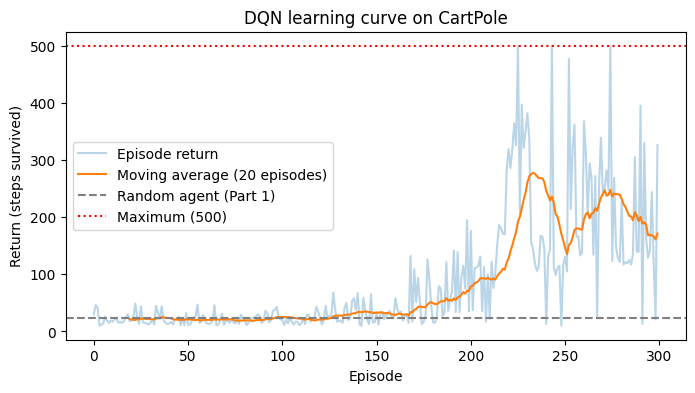

In [14]:
window = 20                                         # moving-average window for smoothing
smooth = np.convolve(dqn_returns, np.ones(window) / window, mode="valid")  # smoothed learning curve
plt.plot(dqn_returns, alpha=0.3, label="Episode return")          # raw returns (faint)
plt.plot(range(window - 1, len(dqn_returns)), smooth, label=f"Moving average ({window} episodes)")  # smoothed curve
plt.axhline(np.mean(random_returns), color="grey", ls="--", label="Random agent (Part 1)")        # baseline
plt.axhline(500, color="red", ls=":", label="Maximum (500)")      # the ceiling
plt.xlabel("Episode"); plt.ylabel("Return (steps survived)")      # axis labels
plt.title("DQN learning curve on CartPole"); plt.legend()          # title and legend
plt.show()                                          # display the figure

#### Reading the output

**What you see:** the faint blue line is the return of each episode, the orange line is the 20-episode moving average, the grey dashed line is the random baseline (22.9), and the red dotted line is the maximum (500).

**Reading the curve:**
* **Episodes 0 to about 140:** the orange line sits on the grey baseline. The agent is no better than random.
* **Episodes about 140 to 210:** a slow rise to about 90, with individual episodes starting to reach 100 to 150.
* **Episodes about 210 to 230:** a sharp rise to a peak moving average of about **275**. Some single episodes reach the **500-step maximum** (near episodes 225, 240 and 273).
* **Episodes about 235 to 250:** a deep dip, to about 140.
* **Episodes about 250 to 280:** a recovery to about 245.
* **Episodes about 280 to 300:** another decline, to about 165, at the moment training stops.

**Why the faint line is so jagged:** even late in training it jumps between 500 and below 50 from one episode to the next. Each episode starts from a different random state, a few random actions remain (ε = 0.02), and the network itself changes after every step.

**Why the dips happen:** a dip after a plateau is sometimes called **catastrophic forgetting**: new updates overwrite what earlier updates learned. Common remedies are a smaller learning rate, a larger replay buffer, Double DQN, or saving the best network during training.

**Key point:** the agent has clearly **learned**. The orange line ends about 7 times above the random baseline. But learning is unstable, and the final network was taken during a downswing.

In [15]:
def evaluate_dqn(q_net, episodes=20, seed=1000):
    # Play episodes with the greedy policy (no exploration) and return the list of returns
    env = gym.make("CartPole-v1")                   # fresh evaluation environment
    results = []                                    # returns of the evaluation episodes
    for i in range(episodes):                       # several test episodes with unseen seeds
        s, _ = env.reset(seed=seed + i)             # seeds 1000+ were never used in training
        total, done = 0.0, False                    # return and end flag
        while not done:                             # play until the episode ends
            with torch.no_grad():                   # inference only, no gradients
                a = int(q_net(torch.tensor(s, dtype=torch.float32)).argmax())  # always the best action
            s, r, term, trunc, _ = env.step(a)      # act
            total += r                              # accumulate reward
            done = term or trunc                    # check for the end of the episode
        results.append(total)                       # store this episode's return
    return results                                  # list of returns

eval_returns = evaluate_dqn(dqn)                    # evaluate the trained agent
print("Greedy DQN returns:", [int(x) for x in eval_returns])       # each test episode's return
print(f"Mean = {np.mean(eval_returns):.1f} ± {np.std(eval_returns):.1f} "
      f"(random agent: {np.mean(random_returns):.1f})")             # compare with the random baseline

Greedy DQN returns: [13, 94, 16, 22, 14, 154, 13, 158, 13, 13, 156, 14, 13, 98, 149, 96, 16, 102, 150, 15]
Mean = 66.0 ± 59.7 (random agent: 22.9)


#### Reading the output

**What you see:**
```
Greedy DQN returns: [13, 94, 16, 22, 14, 154, 13, 158, 13, 13, 156, 14, 13, 98, 149, 96, 16, 102, 150, 15]
Mean = 66.0 ± 59.7 (random agent: 22.9)
```
These are 20 test episodes on seeds 1000 to 1019, which were never used in training, with **no exploration** (always the highest-Q action).

**What it means:**
* **Overall:** the mean of 66.0 is about **2.9 times** the random baseline, so the agent has learned something real. But it is far below the 248.4 seen at the best point of training, and no test episode reached 500.
* **The results fall into two clear groups:**

| Group | Episodes | Returns | Interpretation |
|---|---|---|---|
| Failures | 11 of 20 | 13 to 22 (mostly 13 to 16) | **Worse than the random agent's average.** From these starting states the network keeps pushing the same way and the pole falls almost immediately |
| Partial successes | 9 of 20 | 94 to 158 (mean about 129) | The agent balances for a while, about 5 to 7 times the random level, but then drifts and fails |

* **The large standard deviation (±59.7)** comes from this split. The mean of 66 describes almost none of the actual episodes, and the median is only 19.
* **Why test performance is lower than the training curve:** the network was saved at the end of training, during the downswing seen in the plot above (a moving average of about 165 and falling). The training curve also averages over different starting states, while the test exposes which states the network handles badly.

**How to improve it:** train for more episodes (for example `episodes=500`), use a smaller learning rate, or save and evaluate the best network found during training instead of the last one. Runs that do this often reach the 500-step maximum on most test episodes.

**Key point, and a trustworthiness lesson:** the agent performs well from some starting states and fails badly from others. A good training curve did not guarantee reliable behaviour on unseen conditions. Always evaluate a learned controller on **held-out scenarios**, report the **spread** and not only the mean, and inspect the failure cases before trusting it.

**Part 5 takeaway:** DQN extends Q-learning to a continuous state space and clearly beats random play (66.0 against 22.9 on unseen seeds; up to 248 during training). The same outputs also show its main weakness: unstable training and uneven reliability across starting conditions.

---
# Part 6. Wrap-up

| Method | Needs the model $P$? | State space | Update rule | Result today |
|---|---|---|---|---|
| Epsilon-greedy bandit | No | None (single state) | $Q \leftarrow Q + \tfrac{1}{N}(R - Q)$ | ε = 0.1 picks the best arm 80.4% of the time, against 36.6% for greedy |
| Value Iteration | **Yes** | Small, discrete | Bellman optimality backup | Exact optimum: 74.1% success, against 7.0% for a random policy |
| Q-learning | No | Small, discrete | TD update on a table | 74.1% success with the same policy as the optimum, from experience alone (20,000 episodes) |
| DQN | No | Large or continuous | TD update on a neural network, with replay and a target network | Mean return 66.0 on unseen seeds (about 2.9× the random 22.9), peak training average 248.4; unstable and uneven across starting states |

**Three ideas to remember**
1. **Exploration matters.** A purely greedy agent can lock onto a poor choice forever.
2. **Bootstrapping.** Value Iteration, Q-learning and DQN all improve an estimate using another estimate: target = $r + \gamma \max Q(s', \cdot)$.
3. **Function approximation needs stabilisers.** Neural networks generalise across continuous states, but need experience replay and target networks to train reliably.

## Take-home exercises

1. **Discount factor:** re-run Value Iteration with `gamma=0.9`. How do the values and the policy change, and why?
2. **Deterministic ice:** run Q-learning on `is_slippery=False`. How many episodes are needed, and what success rate is reached?
3. **SARSA:** change the Q-learning target to use the action actually taken next, $Q(s', a')$, instead of $\max_{a'}$. Compare the learned policy with Q-learning.
4. **Double DQN:** in `train_dqn`, choose the next action with `q_net` and evaluate it with `target_net`. Does training become more stable?
5. **New environment:** try DQN on `Acrobot-v1` (6-dimensional state, 3 actions; returns are negative, so higher is better).

## Further reading
* R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press, 2018 (free online).
* V. Mnih et al., "Human-level control through deep reinforcement learning," *Nature*, 518, 529 to 533, 2015.
* Gymnasium documentation: https://gymnasium.farama.org